# Air Quality Index (AQI) Prediction and Forecasting Using Machine Learning
**Mini Project - Machine Learning**

**Objective:** Predict the daily AQI of an Indian city from its recent history and calendar information,
compare several ML models, and forecast the AQI for the next 30 days.

**Dataset:** *Air Quality Data in India (2015-2020)* - `city_day.csv` (Kaggle, CPCB data).


**Pipeline**
1. Load data and select columns -> `air_quality_selected_columns.csv`
2. Clean data, EDA and feature engineering -> `air_quality_analysis.csv`
3. Train and compare models -> `model_comparison.csv`
4. Forecast next 30 days -> `aqi_forecast.csv`

In [1]:
   %pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Import Libraries and Configuration

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_style("whitegrid")

RAW_FILE = "city_day.csv"      # downloaded dataset
CITY = "Delhi"                 # change to any city present in the dataset
FORECAST_DAYS = 30
RANDOM_STATE = 42

## 2. Load Data and Select Columns

In [2]:
raw = pd.read_csv(RAW_FILE)
print("Full dataset shape:", raw.shape)
print("Cities available:", sorted(raw["City"].unique()))
raw.head()

Full dataset shape: (29531, 16)
Cities available: ['Ahmedabad', 'Aizawl', 'Amaravati', 'Amritsar', 'Bengaluru', 'Bhopal', 'Brajrajnagar', 'Chandigarh', 'Chennai', 'Coimbatore', 'Delhi', 'Ernakulam', 'Gurugram', 'Guwahati', 'Hyderabad', 'Jaipur', 'Jorapokhar', 'Kochi', 'Kolkata', 'Lucknow', 'Mumbai', 'Patna', 'Shillong', 'Talcher', 'Thiruvananthapuram', 'Visakhapatnam']


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [3]:
selected_cols = ["City", "Date", "PM2.5", "PM10", "NO2", "SO2", "CO", "O3", "AQI"]
df = raw[raw["City"] == CITY][selected_cols].copy()
df.to_csv("air_quality_selected_columns.csv", index=False)
print(f"Selected data for {CITY}:", df.shape)
df.head()

Selected data for Delhi: (2009, 9)


,City,Date,PM2.5,PM10,NO2,SO2,CO,O3,AQI
10229,Delhi,2015-01-01,313.22,607.98,36.39,9.25,15.20,41.68,472.0
10230,Delhi,2015-01-02,186.18,269.55,32.87,6.65,9.54,29.97,454.0
10231,Delhi,2015-01-03,87.18,131.90,30.31,2.65,10.61,19.71,143.0
10232,Delhi,2015-01-04,151.84,241.84,36.91,4.63,11.54,25.36,319.0
10233,Delhi,2015-01-05,146.60,219.13,34.92,3.33,9.20,23.20,325.0


## 3. Data Cleaning

In [4]:
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").set_index("Date").drop(columns="City")

print("Missing values before cleaning:")
print(df.isna().sum())

Missing values before cleaning:
PM2.5      2
PM10      77
NO2        2
SO2      110
CO         0
O3        84
AQI       10
dtype: int64


In [5]:
# Make the series continuous (one row per day), then fill gaps using interpolation
full_range = pd.date_range(df.index.min(), df.index.max(), freq="D")
df = df.reindex(full_range)
df.index.name = "Date"

df = df.interpolate(method="time", limit_direction="both")
df = df.dropna(subset=["AQI"])

print("Missing values after cleaning:")
print(df.isna().sum().sum())
df.describe().round(2)

Missing values after cleaning:
0


,PM2.5,PM10,NO2,SO2,CO,O3,AQI
count,2009.00,2009.00,2009.00,2009.00,2009.00,2009.00,2009.00
mean,117.10,231.10,50.80,15.63,1.98,50.30,258.62
std,82.92,121.06,22.69,7.98,2.56,26.03,119.90
min,10.24,18.59,10.63,2.34,0.00,6.94,29.00
25%,57.08,136.58,33.90,10.11,0.91,32.77,159.00
50%,94.49,214.05,47.15,14.31,1.24,43.29,257.00
75%,152.99,309.18,63.57,19.53,1.87,59.88,345.00
max,685.36,796.88,162.50,71.56,30.44,257.73,716.00


## 4. Exploratory Data Analysis

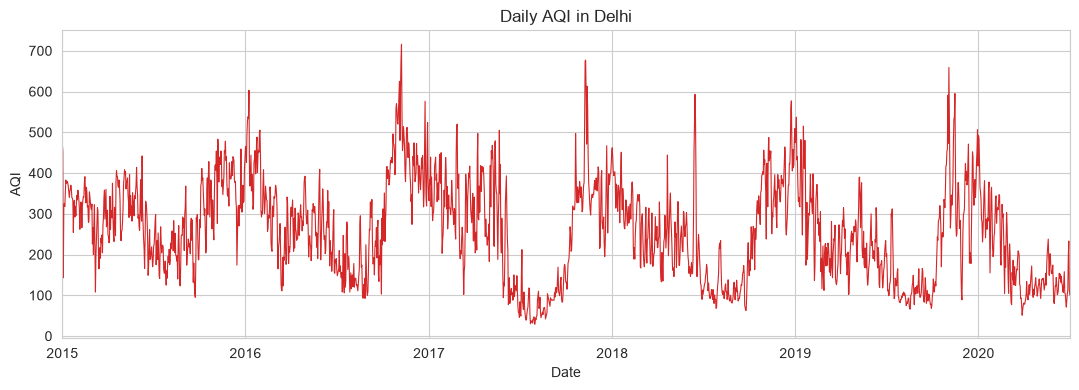

In [6]:
fig, ax = plt.subplots(figsize=(13, 4))
df["AQI"].plot(ax=ax, color="tab:red", linewidth=0.8)
ax.set_title(f"Daily AQI in {CITY}")
ax.set_ylabel("AQI")
plt.show()

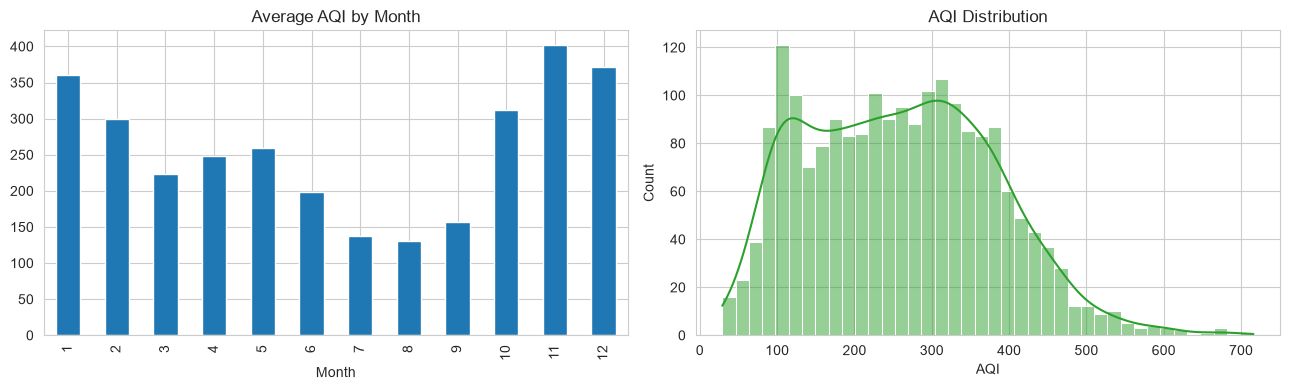

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
monthly = df.groupby(df.index.month)["AQI"].mean()
monthly.plot(kind="bar", ax=axes[0], color="tab:blue")
axes[0].set_title("Average AQI by Month")
axes[0].set_xlabel("Month")

sns.histplot(df["AQI"], bins=40, kde=True, ax=axes[1], color="tab:green")
axes[1].set_title("AQI Distribution")
plt.tight_layout()
plt.show()

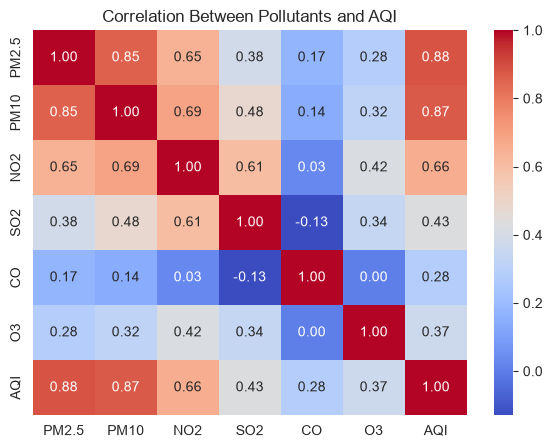

In [8]:
plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Between Pollutants and AQI")
plt.show()

## 5. Feature Engineering
AQI depends strongly on recent days and on the season, so we create lag features, a 7-day rolling mean and calendar features.

In [9]:
data = df[["AQI"]].copy()
data["month"] = data.index.month
data["dayofweek"] = data.index.dayofweek
data["dayofyear"] = data.index.dayofyear
data["aqi_lag1"] = data["AQI"].shift(1)
data["aqi_lag2"] = data["AQI"].shift(2)
data["aqi_lag7"] = data["AQI"].shift(7)
data["aqi_roll7"] = data["AQI"].shift(1).rolling(7).mean()
data = data.dropna()

data.to_csv("air_quality_analysis.csv")
print("Final modelling data:", data.shape)
data.head()

Final modelling data: (2002, 8)


,AQI,month,dayofweek,dayofyear,aqi_lag1,aqi_lag2,aqi_lag7,aqi_roll7
Date,,,,,,,,
2015-01-08,383.0,1,3,8,353.0,318.0,472.0,340.571429
2015-01-09,375.0,1,4,9,383.0,353.0,454.0,327.857143
2015-01-10,376.0,1,5,10,375.0,383.0,143.0,316.571429
2015-01-11,379.0,1,6,11,376.0,375.0,319.0,349.857143
2015-01-12,375.0,1,0,12,379.0,376.0,325.0,358.428571


## 6. Train-Test Split
This is time-series data, so we split **by time** (first 80% train, last 20% test) instead of splitting randomly.

In [10]:
FEATURES = ["month", "dayofweek", "dayofyear", "aqi_lag1", "aqi_lag2", "aqi_lag7", "aqi_roll7"]
X, y = data[FEATURES], data["AQI"]

split = int(len(data) * 0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (1601, 7) | Test: (401, 7)


## 7. Model Training and Comparison

In [11]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, random_state=RANDOM_STATE),
}

results, predictions = [], {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    predictions[name] = pred
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred),
    })

comparison = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True).round(3)
comparison.to_csv("model_comparison.csv", index=False)
comparison

,Model,MAE,RMSE,R2
0,Linear Regression,31.786,43.533,0.853
1,Ridge Regression,31.787,43.534,0.853
2,Random Forest,31.563,43.957,0.850
3,Gradient Boosting,32.220,44.534,0.846


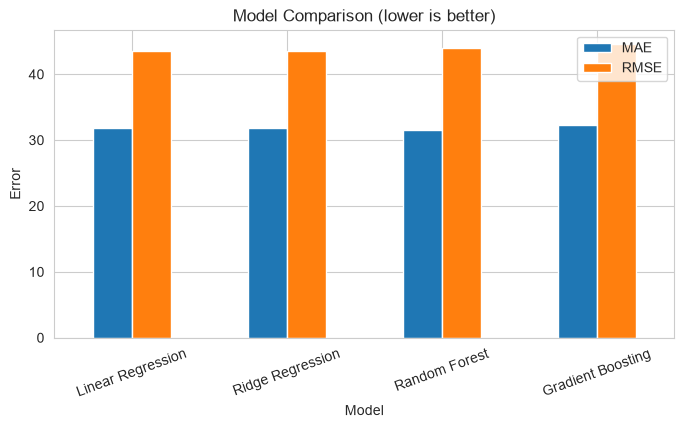

In [12]:
comparison.set_index("Model")[["MAE", "RMSE"]].plot(kind="bar", figsize=(8, 4))
plt.title("Model Comparison (lower is better)")
plt.xticks(rotation=20)
plt.ylabel("Error")
plt.show()

Best model: Linear Regression


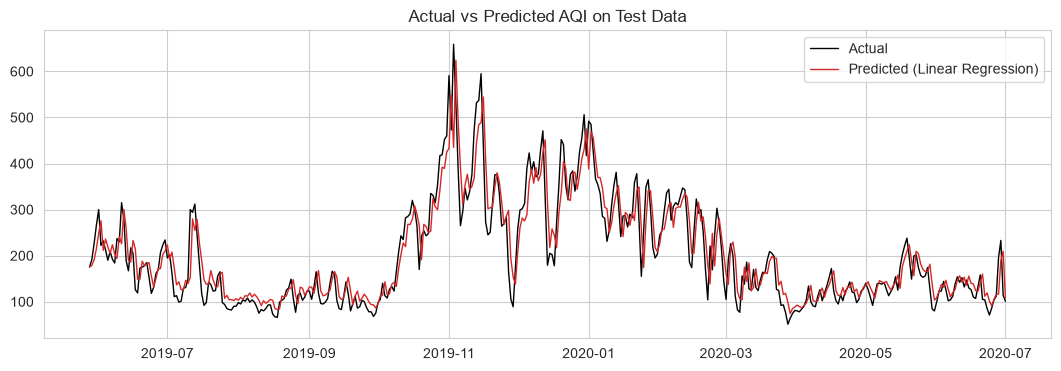

In [13]:
best_name = comparison.loc[0, "Model"]
print("Best model:", best_name)

plt.figure(figsize=(13, 4))
plt.plot(y_test.index, y_test.values, label="Actual", color="black", linewidth=1)
plt.plot(y_test.index, predictions[best_name], label=f"Predicted ({best_name})", color="tab:red", linewidth=1)
plt.title("Actual vs Predicted AQI on Test Data")
plt.legend()
plt.show()

## 8. Forecast the Next 30 Days
The best model is retrained on all data and predicts one day at a time. Each prediction is fed back as the lag input for the next day (recursive forecasting).

In [14]:
best_model = models[best_name]
best_model.fit(X, y)

def aqi_bucket(v):
    if v <= 50:  return "Good"
    if v <= 100: return "Satisfactory"
    if v <= 200: return "Moderate"
    if v <= 300: return "Poor"
    if v <= 400: return "Very Poor"
    return "Severe"

history = list(data["AQI"].values)
last_date = data.index[-1]
rows = []
for i in range(1, FORECAST_DAYS + 1):
    d = last_date + pd.Timedelta(days=i)
    feat = pd.DataFrame([{
        "month": d.month, "dayofweek": d.dayofweek, "dayofyear": d.dayofyear,
        "aqi_lag1": history[-1], "aqi_lag2": history[-2], "aqi_lag7": history[-7],
        "aqi_roll7": np.mean(history[-7:]),
    }])[FEATURES]
    p = float(best_model.predict(feat)[0])
    history.append(p)
    rows.append({"Date": d.date(), "Predicted_AQI": round(p, 2), "AQI_Category": aqi_bucket(p)})

forecast = pd.DataFrame(rows)
forecast.to_csv("aqi_forecast.csv", index=False)
forecast.head(10)

,Date,Predicted_AQI,AQI_Category
0,2020-07-02,117.51,Moderate
1,2020-07-03,135.27,Moderate
2,2020-07-04,148.23,Moderate
3,2020-07-05,158.96,Moderate
4,2020-07-06,167.46,Moderate
5,2020-07-07,166.89,Moderate
6,2020-07-08,165.85,Moderate
7,2020-07-09,167.29,Moderate
8,2020-07-10,170.47,Moderate
9,2020-07-11,174.02,Moderate


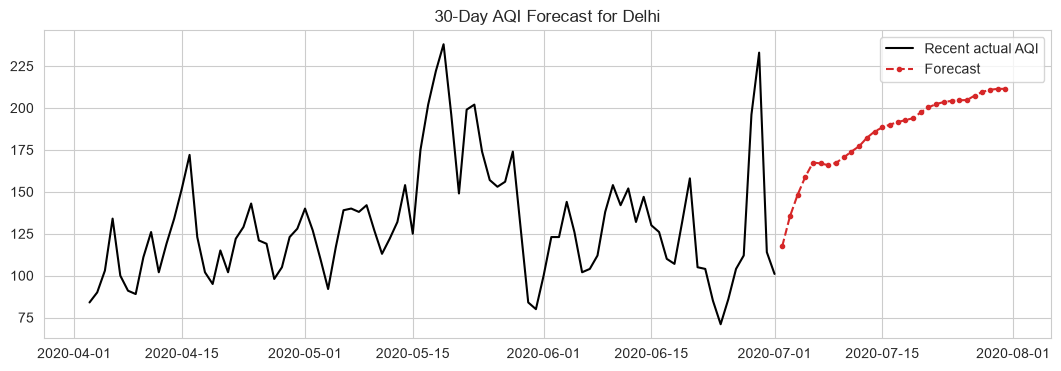

In [15]:
plt.figure(figsize=(13, 4))
recent = data["AQI"].iloc[-90:]
plt.plot(recent.index, recent.values, label="Recent actual AQI", color="black")
plt.plot(pd.to_datetime(forecast["Date"]), forecast["Predicted_AQI"],
         label="Forecast", color="tab:red", linestyle="--", marker="o", markersize=3)
plt.title(f"{FORECAST_DAYS}-Day AQI Forecast for {CITY}")
plt.legend()
plt.show()

## 9. Conclusion
- The best performing model was selected using RMSE, MAE and R2 on unseen (future) test data.
- Recent AQI values (lag features) and the season are strong predictors of the next day's AQI.
- Recursive forecasting becomes less reliable the further ahead we predict, because errors accumulate.
